In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [3]:
observables1 = ['pt','b','w','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','ws','y1s','y2s','phi1s','phi2s','nefs']

In [31]:
df_allreco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and w<1')

In [3]:
df_allreco = applyCut(pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/all050124_rc.csv', low_memory=False),\
                      'pts>15 and bs!=-9 and w<1')

In [33]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

Process PYTHIA6+GEANT

In [4]:
df_match = applyCut(df_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')

In [5]:
print(df_match.shape[0], df_allfake.shape[0])

2623349 1471810


In [6]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)],\
                       df_allreco[(df_allreco.pts>40) & (df_allreco.pts<60)]]

df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)] ]

df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)],\
                       df_allfake[(df_allfake.pts>40) & (df_allfake.pts<60)]  ]

In [7]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [8]:
plt.rcParams['font.size'] = 12

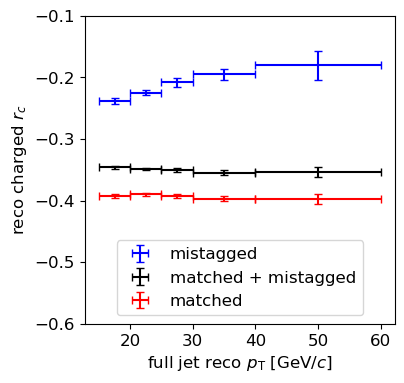

In [9]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')

In [10]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [11]:
b_fake_array = []
for i in range(0,5):
    df_fake_pts = df_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_pts['ws'], density=True)
    b_fake_array.append(y_fake_rec/sum(y_fake_rec))

In [12]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)]  ]

In [13]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

In [14]:
b_match_array = []
b_match_err_array = []
for i in range(0,5):
    df_match_pts = df_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts['ws'], density=True)
    b_match_array.append(y_reco/sum(y_reco))
    b_match_err_array.append(yerr_reco/sum(y_reco))
    print(y_reco/sum(y_reco))

[0.69613888 0.30386112]
[0.69480417 0.30519583]
[0.69601126 0.30398874]
[0.69844548 0.30155452]
[0.69854114 0.30145886]


In [39]:
print(np.asarray(b_match_err_array)/np.asarray(b_match_array))

[[0.00379511 0.00588428]
 [0.00334841 0.00497597]
 [0.00439882 0.00655874]
 [0.00545806 0.00825577]
 [0.01141734 0.01567387]]


In [15]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_2522986/4101531506.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [16]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.29936704, 0.24871283, 0.22295968, 0.20754411, 0.19886014])

$r_c$ correction is not needed

In [17]:
rc_match_b_vs_pt_array = []
rc_err_match_b_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[0])
    rc_err_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[1])

Text(20, -0.2, '$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

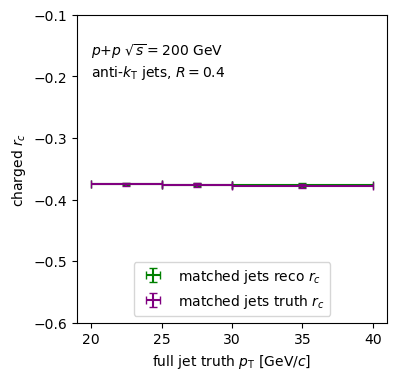

In [18]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='g', ls='none', label='matched jets reco $r_c$')
plt.errorbar([22.5, 27.5, 35], rc_match_b_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_b_vs_pt_array[1:-1], capsize=3, color='purple', ls='none', label='matched jets truth $r_c$')
plt.xlabel('full jet truth $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.2, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')
#plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

In [78]:
print(sum(df_match[(df_match.bs!=df_match.b)]['w'])/sum(df_match['w']))

0.0008088911041101251


In [88]:
print(sum(df_match[(df_match.bs!=df_match.b)&(df_match.pt>20)&(df_match.pts>15)]['w'])/sum(df_match[(df_match.pt>20)&(df_match.pts>15)]['w']))

0.0013635513521262847


In [75]:
print(rc_match_bs_vs_pt_array)
print(rc_match_b_vs_pt_array)

[-0.3899944853242419, -0.37493873476311457, -0.37577417315492717, -0.37661197987356804, -0.3651548525443778]
[-0.3903382403834535, -0.3754814019905652, -0.37643830629285335, -0.3774803068039428, -0.36710937188999626]


Process data

In [19]:
observables1 = ['pt','b']
file = uproot.open('/gpfs/gibbs/project/havener/ys668/rc/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9 and bs!=0')

In [20]:
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [21]:
def getRcAndErrAndN(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err, n

In [22]:
rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[1])

In [23]:
b_data_array = []
for i in range(0,5):
    df_data_pts = df_data_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_data_pts['bs'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
    b_data_array.append(y_reco)

# 1. Mistagged subtraction

In [24]:
def getMatchedCountAndErr(data, fake_rate, fake_dist):
    corrected = data - sum(data) * fake_rate * fake_dist
    err = np.sqrt(corrected)
    return corrected, err

In [16]:
#fake_rate_array = np.array([0.29936704, 0.24871283, 0.22295968, 0.20754411, 0.19886014])
#b_fake_array = np.array([[0.61905176, 0.38094824],[0.61242198, 0.38757802],[0.60408262, 0.39591738],[0.5976935, 0.4023065],[0.59006909, 0.40993091]])

In [25]:
b_fakesubtracted_array = []
b_fakesubtractederr_array = []
rc1_array = []
rc1_err_array = []
for i in range(0,5):
    print(i)
    print(b_data_array[i])
    #print(getRc(data_array[i]))
    b_fakesubtracted, b_fakesubtractederr = getMatchedCountAndErr(b_data_array[i], fake_rate_array[i], b_fake_array[i])
    b_fakesubtracted_array.append(b_fakesubtracted)
    b_fakesubtractederr_array.append(b_fakesubtractederr)
    print(b_fakesubtracted)
    print(b_fakesubtractederr)
    nos = b_fakesubtracted[0]
    nss = b_fakesubtracted[1]
    n = nos + nss
    p = nss / n
    rc1 = (nss-nos) / (nss+nos)
    rc1_array.append(rc1)
    rc1_err_array.append( 2*np.sqrt(p*(1-p)/n) )

0
[337314. 178144.]
[241787.4194556  119359.44336324]
[491.71884188 345.48436052]
1
[72379. 38554.]
[55481.99560278 27860.54405046]
[235.54616448 166.9147808 ]
2
[16450.  8688.]
[13064.26158427  6468.97787029]
[114.2990008  80.4299563]
3
[4758. 2573.]
[3848.60584569 1960.88829996]
[62.0371328  44.28191843]
4
[334. 153.]
[276.85482568 113.30028798]
[16.63895507 10.6442608 ]


In [26]:
print(np.asarray(b_fakesubtractederr_array)/np.asarray(b_fakesubtracted_array))

[[0.00203368 0.00289449]
 [0.00424545 0.00599108]
 [0.00874898 0.01243318]
 [0.01611938 0.02258258]
 [0.06009993 0.09394734]]


In [29]:
print(rc_data_bs_vs_pts_array)

[-0.3087933449476, -0.3049137767841851, -0.30877555891479036, -0.2980493793479744, -0.37166324435318276]


Text(20, -0.2, '$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

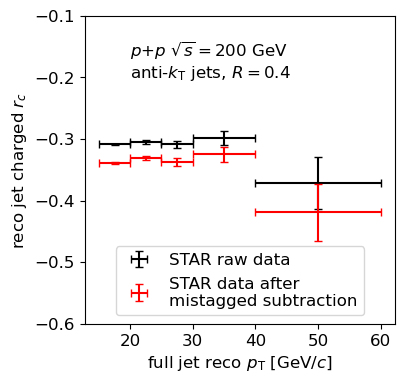

In [30]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_data_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_data_bs_vs_pts_array, capsize=3, color='k', ls='none', label='STAR raw data')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='STAR data after\nmistagged subtraction')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.2, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

# 2. $p_T$ correction

In [27]:
reweight_array = []
reweight_err_array = []
for i in range(0,5):
    numerator = b_fakesubtracted_array[i]/sum(b_fakesubtracted_array[i])
    denominator = b_match_array[i]/sum(b_match_array[i])
    numerator_err = b_fakesubtractederr_array[i]/sum(b_fakesubtracted_array[i])
    denominator_err = b_match_err_array[i]/sum(b_match_array[i])
    reweight = numerator/denominator
    reweight_err = reweight*np.sqrt((numerator_err/numerator)**2+(denominator_err/denominator)**2)
    reweight_array.append(reweight)
    reweight_err_array.append(reweight_err)

In [28]:
reweight_array

[array([0.96173177, 1.08767165]),
 array([0.95812666, 1.09532821]),
 array([0.9609357 , 1.08944143]),
 array([0.94848967, 1.11930564]),
 array([1.01583414, 0.96330909])]

In [29]:
reweight_err_array

[array([0.00414089, 0.00713257]),
 array([0.0051806 , 0.00853044]),
 array([0.00941002, 0.01531435]),
 array([0.01614174, 0.02691297]),
 array([0.06214346, 0.0917512 ])]

([], [])

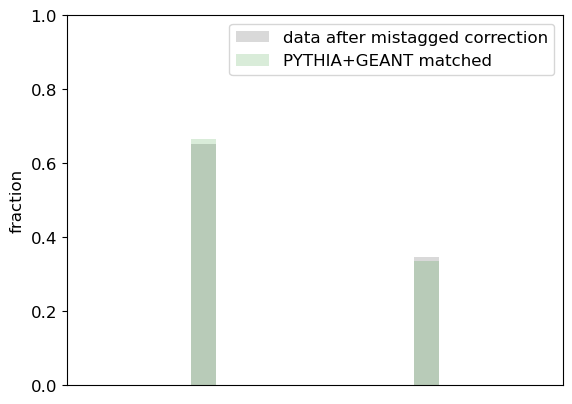

In [63]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=b_data_array[1]/sum(b_data_array[1]), color='k', alpha=0.15, label='data after mistagged correction')
plt.hist(x, weights=b_fakesubtracted_array[1]/sum(b_fakesubtracted_array[1]), ls='none', color='g', alpha=0.15, label='PYTHIA+GEANT matched')
#plt.errorbar(x+np.array([0.05,-0.05]), b_data_array[1][0]/sum(b_data_array[1]), yerr=y1err_array[0]/sum(b_data_array[1]), capsize=3, color='k', ls='none')
#plt.errorbar(x+np.array([0.05,-0.05]), b_fakesubtracted_array[1][0]/sum(b_fakesubtracted_array[1]), yerr=y1err_pythia_array[0]/sum(b_fakesubtracted_array[1]), capsize=3, color='g', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

Reweight PYTHIA6+GEANT

In [30]:
r = []
for i in range(0, df_match.shape[0]):
    if (df_match.iloc[i]['pts'] > 15 and df_match.iloc[i]['pts'] < 20):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df_match.iloc[i]['pts'] > 20 and df_match.iloc[i]['pts'] < 25):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df_match.iloc[i]['pts'] > 25 and df_match.iloc[i]['pts'] < 30):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df_match.iloc[i]['pts'] > 30 and df_match.iloc[i]['pts'] < 40):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df_match.iloc[i]['pts'] > 40 and df_match.iloc[i]['pts'] < 60):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df_match.iloc[i]['pts'])
df_match['r'] = r #

anomaly reco pT: 64.71016459194377
anomaly reco pT: 60.15327606289669
anomaly reco pT: 62.85370544327776
anomaly reco pT: 62.96298659444578
anomaly reco pT: 60.49772873075676
anomaly reco pT: 60.46706627268168
anomaly reco pT: 64.14492779876475
anomaly reco pT: 60.89421353610575
anomaly reco pT: 65.35667922469173
anomaly reco pT: 62.63427678982773
anomaly reco pT: 60.21434194892271
anomaly reco pT: 62.15032283200955
anomaly reco pT: 60.27780299483247
anomaly reco pT: 61.03197986884235
anomaly reco pT: 60.25483540234041
anomaly reco pT: 63.99508646678217
anomaly reco pT: 61.56890722000404
anomaly reco pT: 60.8697641572812
anomaly reco pT: 64.23631221912824
anomaly reco pT: 63.19369788337173
anomaly reco pT: 60.96653998630141
anomaly reco pT: 62.74602930593176
anomaly reco pT: 65.45530859825888
anomaly reco pT: 60.03476303183356
anomaly reco pT: 63.08582949712376
anomaly reco pT: 66.83963074901102
anomaly reco pT: 61.03609940388197
anomaly reco pT: 70.61911542903617
anomaly reco pT: 64.2

anomaly reco pT: 61.45938905164215
anomaly reco pT: 60.16641125403288
anomaly reco pT: 60.09958144920835
anomaly reco pT: 60.511466054485055
anomaly reco pT: 62.350066426895815
anomaly reco pT: 66.11940247976565
anomaly reco pT: 62.15143279465398
anomaly reco pT: 60.697240773348895
anomaly reco pT: 61.79922547972766
anomaly reco pT: 62.11664288908429
anomaly reco pT: 66.38356449440559
anomaly reco pT: 70.6974465514885
anomaly reco pT: 62.49202362716819
anomaly reco pT: 61.065188221162096
anomaly reco pT: 61.23578848561933
anomaly reco pT: 61.52889434809697
anomaly reco pT: 60.31175466428895
anomaly reco pT: 63.22603510311757
anomaly reco pT: 60.18760080128897
anomaly reco pT: 62.83126138185055
anomaly reco pT: 61.152388176492224
anomaly reco pT: 63.75458910527901
anomaly reco pT: 68.07779701999323
anomaly reco pT: 60.92194379917718
anomaly reco pT: 60.93417972296193
anomaly reco pT: 61.33390390171952
anomaly reco pT: 61.446439875350215
anomaly reco pT: 60.71409440105025
anomaly reco pT

anomaly reco pT: 60.55812705404159
anomaly reco pT: 61.28085631237634
anomaly reco pT: 61.47743287524335
anomaly reco pT: 60.488095763928925
anomaly reco pT: 68.54885901919411
anomaly reco pT: 61.50396984848846
anomaly reco pT: 64.2182142798535
anomaly reco pT: 69.73367420432969
anomaly reco pT: 61.027595087508125
anomaly reco pT: 69.64749622782676
anomaly reco pT: 60.80583130708745
anomaly reco pT: 63.75691841415262
anomaly reco pT: 62.728856238000006
anomaly reco pT: 61.4228375011994
anomaly reco pT: 63.19510727748455
anomaly reco pT: 69.17229053514693
anomaly reco pT: 63.03810647468715
anomaly reco pT: 65.11635047674382
anomaly reco pT: 62.7859012143824
anomaly reco pT: 62.68461884512906
anomaly reco pT: 62.91586926703116
anomaly reco pT: 66.29737410911332
anomaly reco pT: 63.565336097220666
anomaly reco pT: 63.24551244561167
anomaly reco pT: 63.80560504086096
anomaly reco pT: 62.089369272962
anomaly reco pT: 62.74313779141439
anomaly reco pT: 63.9898512281929
anomaly reco pT: 61.09

anomaly reco pT: 61.947579640882736
anomaly reco pT: 63.46254812809013
anomaly reco pT: 62.96891790372958
anomaly reco pT: 64.35138414682795
anomaly reco pT: 64.48172194800236
anomaly reco pT: 61.26632928367613
anomaly reco pT: 63.2261305431496
anomaly reco pT: 61.77634558122546
anomaly reco pT: 60.86607307973257
anomaly reco pT: 60.21395499719272
anomaly reco pT: 60.09408616047344
anomaly reco pT: 60.99685047564388
anomaly reco pT: 60.16363338769977
anomaly reco pT: 63.69926317750572
anomaly reco pT: 61.18161983304836
anomaly reco pT: 63.467185073066815
anomaly reco pT: 60.22592505442527
anomaly reco pT: 61.92570005906014
anomaly reco pT: 63.16007891504917
anomaly reco pT: 62.374430308458464
anomaly reco pT: 68.10892590647273
anomaly reco pT: 62.795274122240286
anomaly reco pT: 69.26156246975476
anomaly reco pT: 64.88739968104146
anomaly reco pT: 62.42580563106932
anomaly reco pT: 63.80538779550728
anomaly reco pT: 63.51637813497289
anomaly reco pT: 65.08008710926943
anomaly reco pT: 

anomaly reco pT: 65.7725494015351
anomaly reco pT: 63.11734403019368
anomaly reco pT: 63.84290622372178
anomaly reco pT: 60.24441190326755
anomaly reco pT: 61.21301777980847
anomaly reco pT: 70.52696926518031
anomaly reco pT: 60.01734614322692
anomaly reco pT: 61.89856794874568
anomaly reco pT: 62.53743499967594
anomaly reco pT: 62.71933550193654
anomaly reco pT: 60.37218127058552
anomaly reco pT: 62.28750243812882
anomaly reco pT: 67.35165154282551
anomaly reco pT: 62.938599711603416
anomaly reco pT: 62.01210782743407
anomaly reco pT: 60.09198704471758
anomaly reco pT: 60.17424504803381
anomaly reco pT: 60.10060638205464
anomaly reco pT: 63.40587043188994
anomaly reco pT: 65.75117536986112
anomaly reco pT: 61.4706264844495
anomaly reco pT: 63.14821302266603
anomaly reco pT: 61.18929718786077
anomaly reco pT: 62.63637866291327
anomaly reco pT: 72.35126700760344
anomaly reco pT: 60.24854076145046
anomaly reco pT: 60.06684474591112
anomaly reco pT: 66.72767965295104
anomaly reco pT: 61.7

anomaly reco pT: 61.98943265829271
anomaly reco pT: 60.14072676847585
anomaly reco pT: 63.024973501665386
anomaly reco pT: 60.0567265490732
anomaly reco pT: 64.18815491158762
anomaly reco pT: 61.29028912670281
anomaly reco pT: 66.1197452494242
anomaly reco pT: 60.01477676891959
anomaly reco pT: 61.1943075724957
anomaly reco pT: 63.104092615853546
anomaly reco pT: 65.46221402257831
anomaly reco pT: 67.84262142182176
anomaly reco pT: 62.19826158700649
anomaly reco pT: 60.25203076525589
anomaly reco pT: 60.83897627808934
anomaly reco pT: 64.80033887583954
anomaly reco pT: 63.953189816464565
anomaly reco pT: 68.18579633812224
anomaly reco pT: 60.24489623528246
anomaly reco pT: 62.99607569666728
anomaly reco pT: 60.31319164951025
anomaly reco pT: 63.13952524676651
anomaly reco pT: 64.31647831297151
anomaly reco pT: 60.12751863823648
anomaly reco pT: 64.71235854962525
anomaly reco pT: 63.53333506607567
anomaly reco pT: 61.40922404869982
anomaly reco pT: 64.31771915397053
anomaly reco pT: 63.

... (41 outputs left out)

anomaly reco pT: 61.015566483562765
anomaly reco pT: 63.68479475297369
anomaly reco pT: 63.44403644053514
anomaly reco pT: 60.640852377223815
anomaly reco pT: 61.15052196005195
anomaly reco pT: 61.320558796136325
anomaly reco pT: 63.18263686091254
anomaly reco pT: 62.90964663625422
anomaly reco pT: 60.474750604968186
anomaly reco pT: 60.659901373925614
anomaly reco pT: 70.84315464336441
anomaly reco pT: 62.28597908589783
anomaly reco pT: 64.61167983367942
anomaly reco pT: 62.91536082346625
anomaly reco pT: 62.14523538111491
anomaly reco pT: 62.17444143442113
anomaly reco pT: 61.40903024781379
anomaly reco pT: 68.95695226147237
anomaly reco pT: 63.806204523593145
anomaly reco pT: 62.420926890718064
anomaly reco pT: 60.05018073515866
anomaly reco pT: 64.5565719985491
anomaly reco pT: 61.67929391253504
anomaly reco pT: 71.21606575461387
anomaly reco pT: 64.73983423321928
anomaly reco pT: 66.5276093971714
anomaly reco pT: 61.02100350792692
anomaly reco pT: 60.809741703693575
anomaly reco p

anomaly reco pT: 66.65753904743208
anomaly reco pT: 65.75736739534692
anomaly reco pT: 62.22564061464936
anomaly reco pT: 60.7635198147045
anomaly reco pT: 61.267100032309486
anomaly reco pT: 60.20993675154418
anomaly reco pT: 72.18871264816445
anomaly reco pT: 60.48242090877616
anomaly reco pT: 62.33189760944522
anomaly reco pT: 71.94129385517813
anomaly reco pT: 63.00542391489118
anomaly reco pT: 68.43694912640436
anomaly reco pT: 61.33392960310437
anomaly reco pT: 62.654506556834846
anomaly reco pT: 60.73307231072995
anomaly reco pT: 60.303759511477935
anomaly reco pT: 64.49888168197744
anomaly reco pT: 63.84858594516515
anomaly reco pT: 60.010622942237
anomaly reco pT: 64.69390286062303
anomaly reco pT: 62.32698069264111
anomaly reco pT: 63.63411845186029
anomaly reco pT: 60.00478994632899
anomaly reco pT: 63.403271181078914
anomaly reco pT: 62.29828644792972
anomaly reco pT: 61.08513187601476
anomaly reco pT: 62.53458542765311
anomaly reco pT: 61.754438121186
anomaly reco pT: 61.9

anomaly reco pT: 62.40940025958128
anomaly reco pT: 61.54771402270444
anomaly reco pT: 61.26200955246561
anomaly reco pT: 60.49778582338414
anomaly reco pT: 60.97032066497999
anomaly reco pT: 61.36140870644091
anomaly reco pT: 65.41337436969181
anomaly reco pT: 64.57576331775847
anomaly reco pT: 60.82388172181604
anomaly reco pT: 62.34042209197794
anomaly reco pT: 68.41403974868777
anomaly reco pT: 67.13701901699417
anomaly reco pT: 60.76169991150164
anomaly reco pT: 61.15688660921751
anomaly reco pT: 62.9823772250464
anomaly reco pT: 60.13103817975329
anomaly reco pT: 60.25964548017486
anomaly reco pT: 63.60931354818923
anomaly reco pT: 62.064087811569145
anomaly reco pT: 61.7050453440882
anomaly reco pT: 60.80071121614191
anomaly reco pT: 64.42197733905195
anomaly reco pT: 61.61248574547994
anomaly reco pT: 72.04580607500999
anomaly reco pT: 64.0143636951809
anomaly reco pT: 63.958705313210416
anomaly reco pT: 62.32190937407615
anomaly reco pT: 63.67778162425292
anomaly reco pT: 60.0

/tmp/ipykernel_2522986/3883675663.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match['r'] = r #


In [31]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    print(p)
    w_array = np.unique(df['w'])
    err2_array = []
    #variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        #variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [32]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)] ]
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)]  ]

In [33]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[1])
rc_match_bs_vs_pts_array_rw = []
rc_err_match_bs_vs_pts_array_rw = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[1])

0.33188714307254435
0.33188714307254435
0.34090585939830115
0.34090585939830115
0.340880346110499
0.340880346110499
0.34321486736185264
0.34321486736185264
0.3329338876846474
0.3329338876846474
0.3305011219867523
0.3305011219867523
0.33428959768409944
0.33428959768409944
0.3311779331492546
0.3311779331492546
0.3375316767374809
0.3375316767374809
0.29039805968203014
0.29039805968203014


Check that the reweighted embedding is the same as data

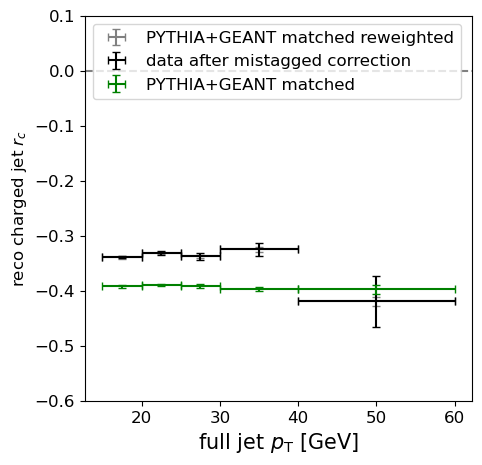

In [96]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array_rw, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array_rw, capsize=3, color='grey', ls='none', label='PYTHIA+GEANT matched reweighted')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='k', ls='none', label='data after mistagged correction')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='g', ls='none', label='PYTHIA+GEANT matched')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [100]:
print(rc_match_bs_vs_pts_array_rw)

[-0.3389977560264954, -0.3314208046318012, -0.33764413370149093, -0.32493664652503856, -0.419203880635934]


Text(20, -0.25, 'STAR data\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

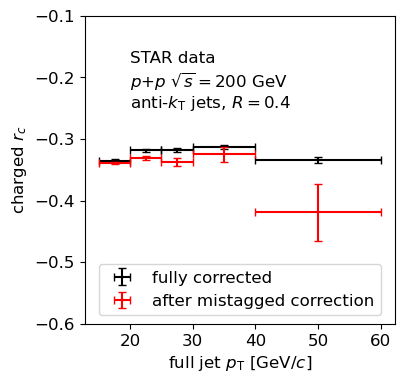

In [105]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='k', ls='none', label='fully corrected')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='after mistagged correction')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.25, 'STAR data\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

Plot result

(-0.6, 0.1)

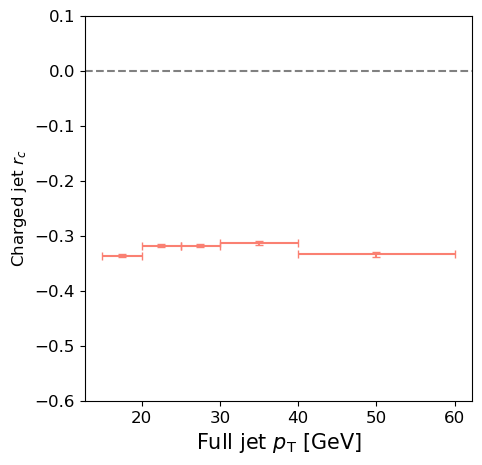

In [97]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='salmon', ls='none', label='sample 1 corrected')
#plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='sample 1 corrected')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.6,0.1)
#plt.legend(loc='upper left', fontsize=15)

In [98]:
rc_match_bs_vs_pt_array

[-0.33622571385491123,
 -0.3181882812033977,
 -0.31823930777900206,
 -0.3135702652762947,
 -0.3341322246307046]

In [99]:
rc_err_match_bs_vs_pt_array

[0.0029097490942195815,
 0.002264048030301499,
 0.002823479322146174,
 0.0035104320098679194,
 0.005306904669499486]

# Check thesis formula

In [47]:
binedges = np.array([15, 20, 25, 30, 40, 60])

In [94]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p_final = nss/(nss+nos)
    print(p_final)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err, p_final

## Truth $p_T\in$ (15, 20) GeV

In [179]:
df_match_cut = applyCut(df_match, '15<pt<20')
df_match_pts_array = [ df_match_cut[(df_match_cut.pts>15) & (df_match_cut.pts<20)],\
                       df_match_cut[(df_match_cut.pts>20) & (df_match_cut.pts<25)],\
                       df_match_cut[(df_match_cut.pts>25) & (df_match_cut.pts<30)],\
                       df_match_cut[(df_match_cut.pts>30) & (df_match_cut.pts<40)],\
                       df_match_cut[(df_match_cut.pts>40) & (df_match_cut.pts<60)] ]

In [180]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.3062855273753735
0.29145912186424
0.2548663415639463
0.4028557241691663
0.2867706788974019


In [181]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '15<pt<20 and bs==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>15) & (df_match_cut.pt<20)]['w'])/sum(df_match_cut[(df_match_cut.pt>15) & (df_match_cut.pt<20)]['w']))
prob_array

[0.9207047759814123,
 0.07799696183274929,
 0.0012430239411480508,
 5.3444209575527985e-05,
 1.7921020340868551e-06]

In [182]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.3319915741457225

In [183]:
np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)

0.0020207071615542635

In [127]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '15<pt<20 and bs==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>15) & (df_match_cut.pt<20)]['w'])/sum(df_match_cut[(df_match_cut.pt>15) & (df_match_cut.pt<20)]['w']))
prob_array

[0.9151564796850777,
 0.08321193656851017,
 0.0015948574585246446,
 3.476570790519904e-05,
 1.9560405832772186e-06]

In [128]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6682157410978843

In [115]:
0.3319915741457225/(0.3319915741457225+0.6682157410978843)

0.331922761497564

## Truth $p_T\in$ (20,25) GeV

In [174]:
df_match_cut = applyCut(df_match, '20<pt<25')
df_match_pts_array = [ df_match_cut[(df_match_cut.pts>15) & (df_match_cut.pts<20)],\
                       df_match_cut[(df_match_cut.pts>20) & (df_match_cut.pts<25)],\
                       df_match_cut[(df_match_cut.pts>25) & (df_match_cut.pts<30)],\
                       df_match_cut[(df_match_cut.pts>30) & (df_match_cut.pts<40)],\
                       df_match_cut[(df_match_cut.pts>40) & (df_match_cut.pts<60)] ]

In [175]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.3207653038345011
0.3089501344205579
0.2916239545871971
0.2569386117394937
0.11103411595080429


In [176]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '20<pt<25 and bs==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>20) & (df_match_cut.pt<25)]['w'])/sum(df_match_cut[(df_match_cut.pt>20) & (df_match_cut.pt<25)]['w']))
prob_array

[0.4098862577769719,
 0.5330160876097,
 0.05542800816895412,
 0.0016631014354267387,
 6.5183035392636705e-06]

In [177]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.34146659350156494

In [178]:
np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)

0.0017070906677523147

In [134]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '20<pt<25 and bs==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>20) & (df_match_cut.pt<25)]['w'])/sum(df_match_cut[(df_match_cut.pt>20) & (df_match_cut.pt<25)]['w']))
prob_array

[0.3945800048835653,
 0.5420015832281795,
 0.06120814017590142,
 0.0021865192207058855,
 2.372479537496792e-05]

In [135]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6598495934660082

In [136]:
0.34146659350156494/(0.34146659350156494+0.6598495934660082)

0.3410177503828

## Truth $p_T\in$ (25, 30) GeV

In [169]:
df_match_cut = applyCut(df_match, '25<pt<30')
df_match_pts_array = [ df_match_cut[(df_match_cut.pts>15) & (df_match_cut.pts<20)],\
                       df_match_cut[(df_match_cut.pts>20) & (df_match_cut.pts<25)],\
                       df_match_cut[(df_match_cut.pts>25) & (df_match_cut.pts<30)],\
                       df_match_cut[(df_match_cut.pts>30) & (df_match_cut.pts<40)],\
                       df_match_cut[(df_match_cut.pts>40) & (df_match_cut.pts<60)] ]

In [170]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.30371844717252744
0.3236422272607208
0.30816585892711973
0.287519140404702
0.1719999210478101


In [171]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '25<pt<30 and bs==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>25) & (df_match_cut.pt<30)]['w'])/sum(df_match_cut[(df_match_cut.pt>25) & (df_match_cut.pt<30)]['w']))
prob_array

[0.11155869730421943,
 0.39056867938889145,
 0.438181322992927,
 0.05953759222673492,
 0.00015352693146433786]

In [172]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.3416033551169046

In [173]:
np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)

0.0023895005911875335

In [141]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '25<pt<30 and bs==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>25) & (df_match_cut.pt<30)]['w'])/sum(df_match_cut[(df_match_cut.pt>25) & (df_match_cut.pt<30)]['w']))
prob_array

[0.11604107237568952,
 0.3703422819561627,
 0.4463401045541351,
 0.06694101430437228,
 0.0003353368506935604]

In [142]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6599506071523044

In [143]:
0.3416033551169046/(0.3416033551169046+0.6599506071523044)

0.34107334001548745

## Truth $p_T\in$ (30, 40) GeV

In [164]:
df_match_cut = applyCut(df_match, '30<pt<40')
df_match_pts_array = [ df_match_cut[(df_match_cut.pts>15) & (df_match_cut.pts<20)],\
                       df_match_cut[(df_match_cut.pts>20) & (df_match_cut.pts<25)],\
                       df_match_cut[(df_match_cut.pts>25) & (df_match_cut.pts<30)],\
                       df_match_cut[(df_match_cut.pts>30) & (df_match_cut.pts<40)],\
                       df_match_cut[(df_match_cut.pts>40) & (df_match_cut.pts<60)] ]

In [165]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.28316726939208137
0.312804485069363
0.32267979995173374
0.3078177404943276
0.29013209461534556


In [166]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '30<pt<40 and bs==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>30) & (df_match_cut.pt<40)]['w'])/sum(df_match_cut[(df_match_cut.pt>30) & (df_match_cut.pt<40)]['w']))
prob_array

[0.04195230335095665,
 0.12298897141520168,
 0.3290355577524411,
 0.4891550158086249,
 0.016865371637292074]

In [167]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.34397750459553056

In [168]:
np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)

0.004402429102836164

In [148]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '30<pt<40 and bs==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>30) & (df_match_cut.pt<40)]['w'])/sum(df_match_cut[(df_match_cut.pt>30) & (df_match_cut.pt<40)]['w']))
prob_array

[0.04809251530119332,
 0.12235463384086036,
 0.3127605653780106,
 0.49810423793932773,
 0.018686354806695987]

In [149]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6577736278276134

In [150]:
0.34397750459553056/(0.34397750459553056+0.6577736278276134)

0.34337620738544167

## Truth $p_T\in$ (40, 60) GeV

In [151]:
df_match_cut = applyCut(df_match, '40<pt<60')
df_match_pts_array = [ df_match_cut[(df_match_cut.pts>15) & (df_match_cut.pts<20)],\
                       df_match_cut[(df_match_cut.pts>20) & (df_match_cut.pts<25)],\
                       df_match_cut[(df_match_cut.pts>25) & (df_match_cut.pts<30)],\
                       df_match_cut[(df_match_cut.pts>30) & (df_match_cut.pts<40)],\
                       df_match_cut[(df_match_cut.pts>40) & (df_match_cut.pts<60)] ]

In [152]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.28959706328906154
0.31010755344048496
0.30695872107519157
0.3234305139550745
0.31483922610251336


In [158]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '40<pt<60 and bs==1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>40) & (df_match_cut.pt<60)]['w'])/sum(df_match_cut[(df_match_cut.pt>40) & (df_match_cut.pt<60)]['w']))
prob_array

[0.014622547924954404,
 0.03500030689545648,
 0.07443239316013701,
 0.45618413517063383,
 0.41877634116171464]

In [159]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.3335419541815301

In [160]:
np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)

0.012737359397516098

In [161]:
prob_array = []
for i in range(0, 5):
    df_match_cut = applyCut(df_match, '40<pt<60 and bs==-1')
    prob_array.append(sum(df_match_cut[(df_match_cut.pts>binedges[i]) & (df_match_cut.pts<binedges[i+1]) & (df_match_cut.pt>40) & (df_match_cut.pt<60)]['w'])/sum(df_match_cut[(df_match_cut.pt>40) & (df_match_cut.pt<60)]['w']))
prob_array

[0.016680902164788267,
 0.03620985493298562,
 0.07814964255957876,
 0.4437695312428447,
 0.4238104688952175]

In [162]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6671283343492007

In [163]:
np.sqrt((reweight_err_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0])**2+\
        (reweight_err_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1])**2+\
        (reweight_err_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2])**2+\
        (reweight_err_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3])**2+\
        (reweight_err_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4])**2)

0.018692048828532523

In [157]:
0.3335419541815301/(0.3335419541815301+0.6671283343492007)

0.3333185345907139

Check that the reweighted embedding is the same as data

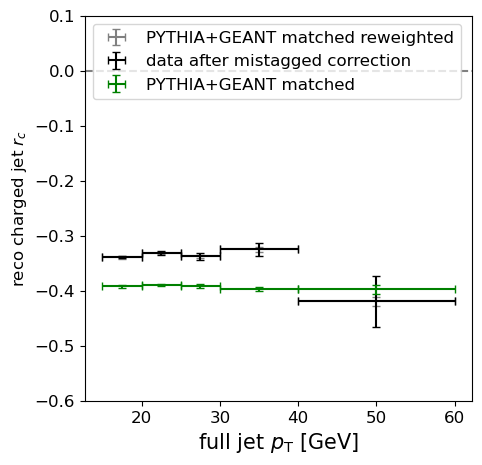

In [96]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array_rw, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array_rw, capsize=3, color='grey', ls='none', label='PYTHIA+GEANT matched reweighted')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='k', ls='none', label='data after mistagged correction')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='g', ls='none', label='PYTHIA+GEANT matched')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [100]:
print(rc_match_bs_vs_pts_array_rw)

[-0.3389977560264954, -0.3314208046318012, -0.33764413370149093, -0.32493664652503856, -0.419203880635934]


Text(20, -0.25, 'STAR data\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

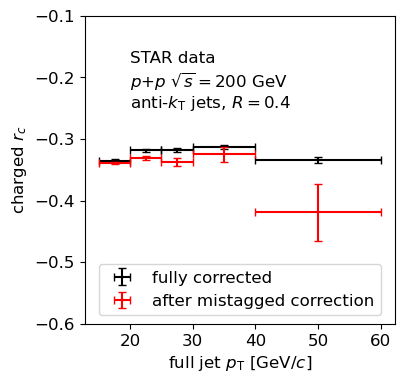

In [105]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='k', ls='none', label='fully corrected')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='after mistagged correction')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.25, 'STAR data\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

Plot result

(-0.6, 0.1)

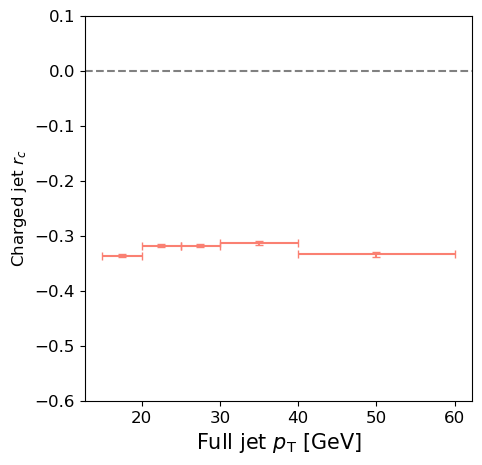

In [97]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='salmon', ls='none', label='sample 1 corrected')
#plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='sample 1 corrected')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.6,0.1)
#plt.legend(loc='upper left', fontsize=15)

In [98]:
rc_match_bs_vs_pt_array

[-0.33622571385491123,
 -0.3181882812033977,
 -0.31823930777900206,
 -0.3135702652762947,
 -0.3341322246307046]

In [99]:
rc_err_match_bs_vs_pt_array

[0.0029097490942195815,
 0.002264048030301499,
 0.002823479322146174,
 0.0035104320098679194,
 0.005306904669499486]

Check efficiency correction is not needed

In [42]:
df_alltruth = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_final.root', "MatchedTree"),\
              'pt>15 and b!=-9 and reject<=0 and rejects<=0')

In [43]:
df_alltruth_pt_array = [ df_alltruth[(df_alltruth.pt>15) & (df_alltruth.pt<20)],\
                       df_alltruth[(df_alltruth.pt>20) & (df_alltruth.pt<25)],\
                       df_alltruth[(df_alltruth.pt>25) & (df_alltruth.pt<30)],\
                       df_alltruth[(df_alltruth.pt>30) & (df_alltruth.pt<40)] ]

In [44]:
rc_alltruth_b_vs_pt_array = []
rc_err_alltruth_b_vs_pt_array = []
for i in range(0, len(df_alltruth_pt_array)):
    rc_alltruth_b_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b')[0])
    rc_err_alltruth_b_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b')[1])

In [45]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

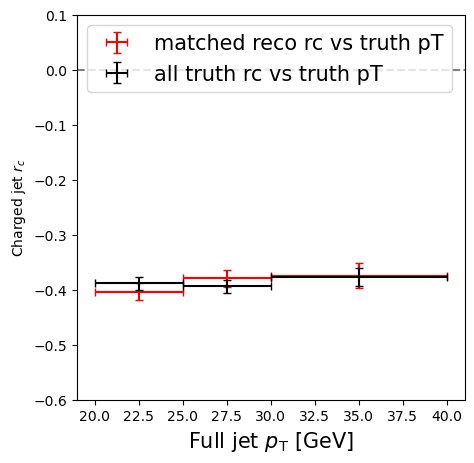

In [46]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:], capsize=3, color='r', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([22.5, 27.5, 35], rc_alltruth_b_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_alltruth_b_vs_pt_array[1:], capsize=3, color='k', ls='none', label='all truth rc vs truth pT')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left', fontsize=15)